In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import graphviz 

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split, KFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import tree
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

In [3]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
df.shape

(1025, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [6]:
df.isnull().sum().sum()

np.int64(0)

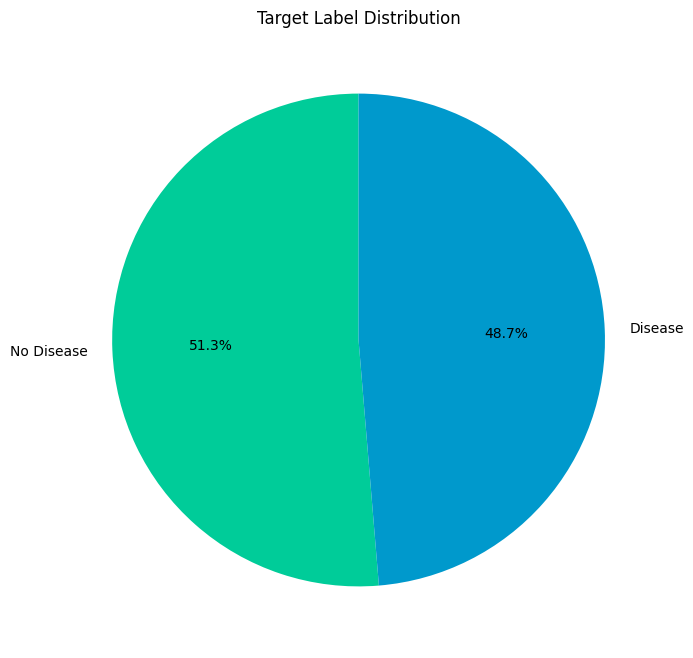

In [7]:
target_counts = df['target'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(target_counts, labels=['No Disease', 'Disease'], autopct='%1.1f%%', startangle=90, colors=['#00cc99', '#0099cc'])
plt.title('Target Label Distribution')
plt.show()

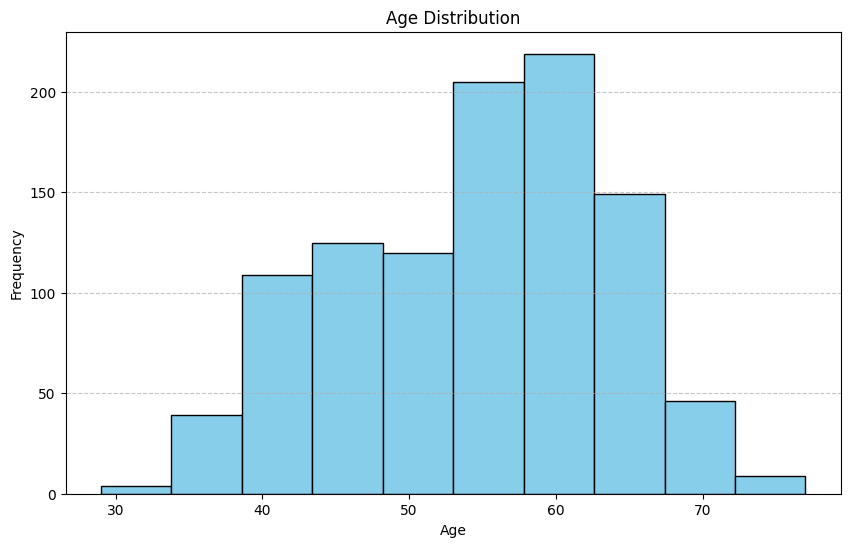

In [8]:
plt.figure(figsize=(10, 6))
plt.hist(df['age'], bins=10, color='skyblue', edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

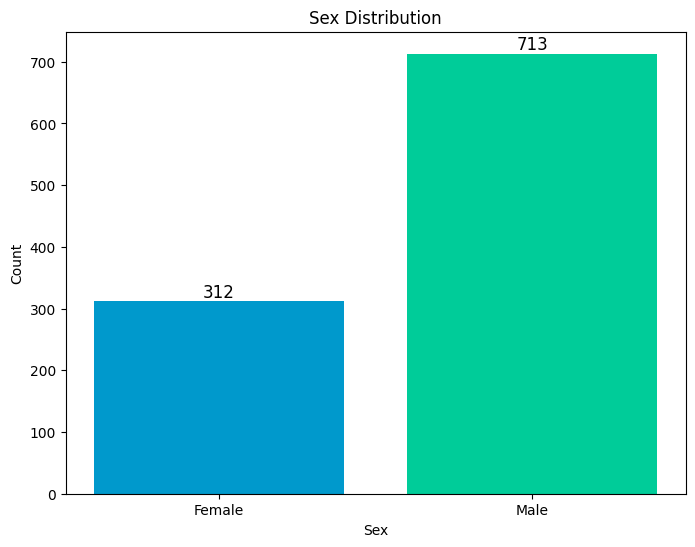

In [9]:
plt.figure(figsize=(8, 6))
sex_counts = df['sex'].value_counts()
bars = plt.bar(sex_counts.index, sex_counts.values, color=['#00cc99', '#0099cc'])
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,  
        bar.get_height(),  
        str(bar.get_height()),  
        ha='center', 
        va='bottom', 
        fontsize=12 
    )
plt.xticks(ticks=[0, 1], labels=['Female', 'Male'])
plt.title('Sex Distribution')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.show()


C:\Users\INFINITYv\AppData\Local\Temp\ipykernel_17164\2471928769.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y='chol', data=df, palette='Set2')


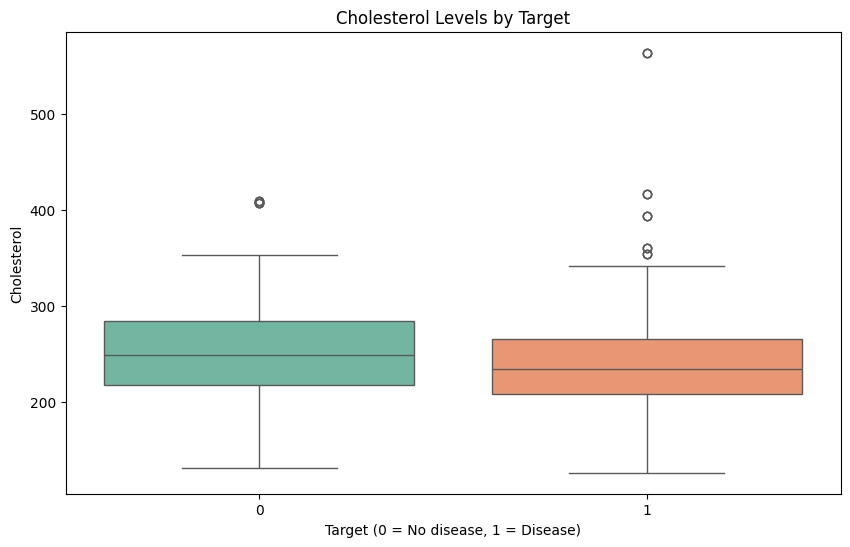

In [10]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='target', y='chol', data=df, palette='Set2')
plt.title('Cholesterol Levels by Target')
plt.xlabel('Target (0 = No disease, 1 = Disease)')
plt.ylabel('Cholesterol')
plt.show()

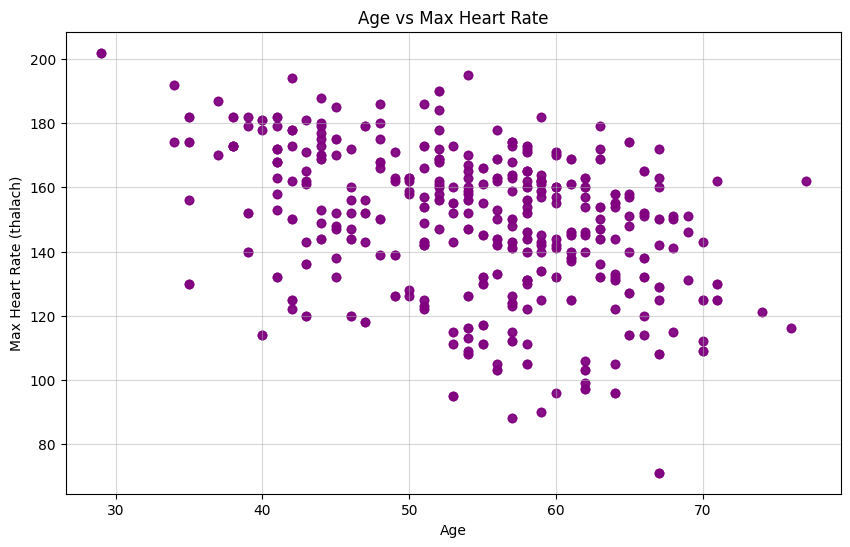

In [11]:
plt.figure(figsize=(10, 6))
plt.scatter(df['age'], df['thalach'], color='purple', alpha=0.6)
plt.title('Age vs Max Heart Rate')
plt.xlabel('Age')
plt.ylabel('Max Heart Rate (thalach)')
plt.grid(alpha=0.5)
plt.show()


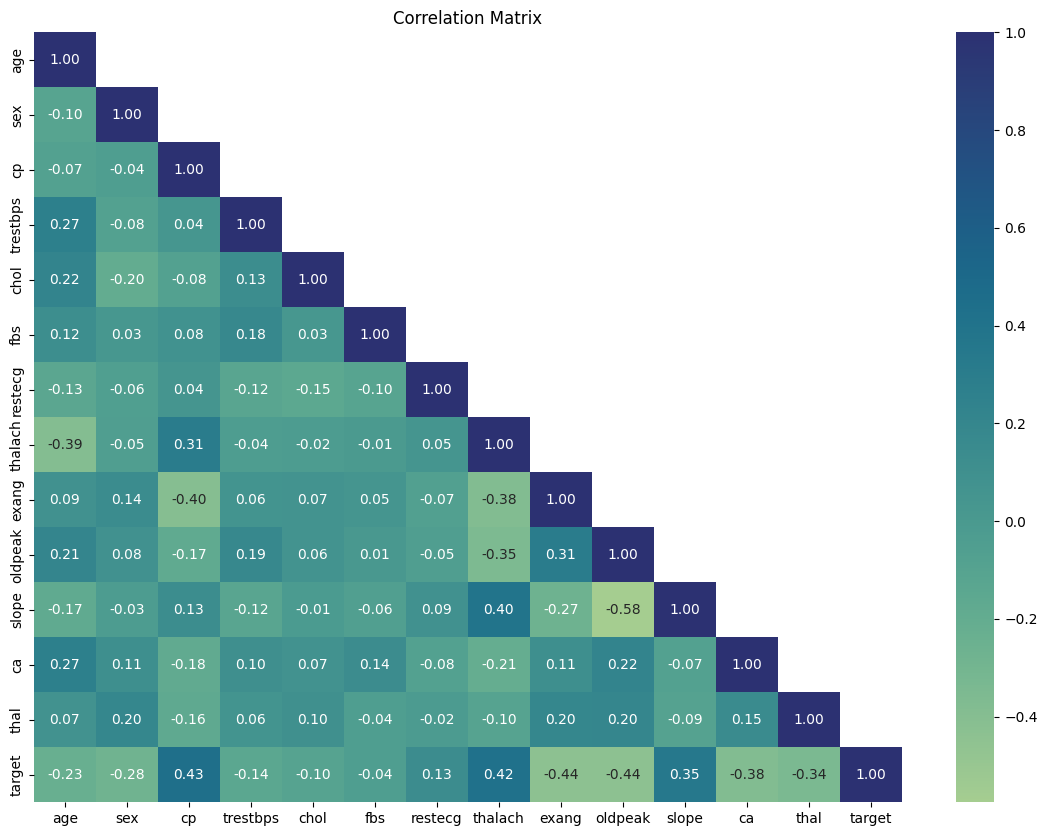

In [12]:
plt.figure(figsize=(14, 10))
correlation_matrix = df.corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt=".2f", cbar=True, cmap="crest")
plt.title('Correlation Matrix')
plt.show()

In [13]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((820, 13), (205, 13))

In [14]:
stander = StandardScaler()
X_train = stander.fit_transform(X_train)
X_test = stander.transform(X_test)

In [15]:
def Gridsearch_params(X, y, model, param_grid, k=5):
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=k,  
        scoring='accuracy', 
        verbose=1,  
        n_jobs=-1  
    )
    grid_search.fit(X, y)
    
    best_model = grid_search.best_estimator_

    print("Best parameters found:", grid_search.best_params_)
    print("Best mean cross-validation accuracy:", round(grid_search.best_score_ * 100, 2), "%\n")
    
    return best_model

In [16]:
def evolution_models(model):
    # Predicting class labels
    y_pred = model.predict(X_test)
    
    # Classification Report
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("------------------------------------------")

    # Confusion Matrix
    labels = df['target'].unique()
    labels = list(labels)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="crest", xticklabels=labels, yticklabels=labels)
    plt.title("Confusion Matrix Heatmap:")
    plt.xlabel("Actual Labels")
    plt.ylabel("Predicted Labels")
    plt.show()

    # AUC-ROC Evaluation
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]  # Probabilities for the positive class
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)  # Decision scores for the positive class
    else:
        raise ValueError("Model does not support probability or decision function output.")

    auc_score = roc_auc_score(y_test, y_prob)
    print(f"AUC-ROC Score: {auc_score:.4f}")

    # Plotting ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
    plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
    plt.title("ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

------------------------------------------


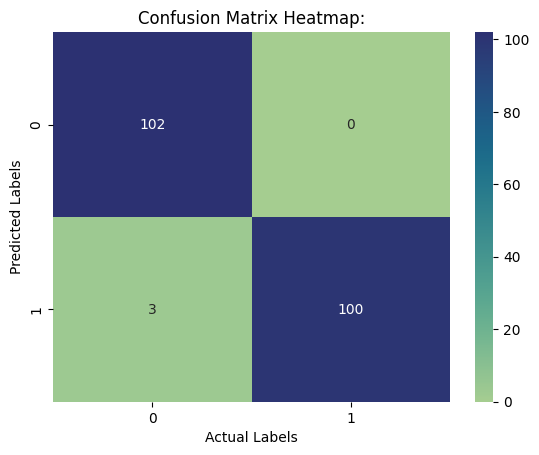

AUC-ROC Score: 0.9854


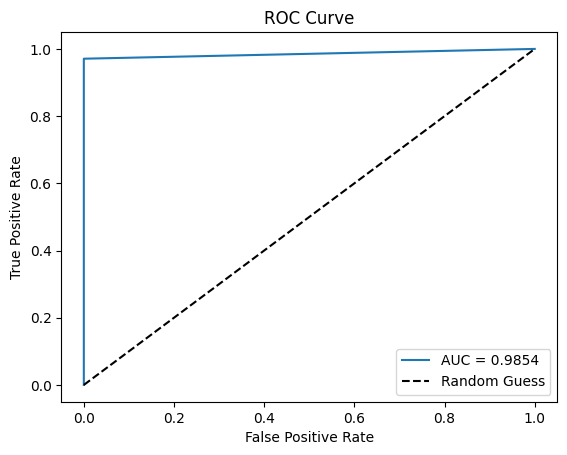

In [17]:
tree_gini = DecisionTreeClassifier(criterion='gini').fit(X_train, y_train)
evolution_models(tree_gini)

[Text(0.5338983050847458, 0.9545454545454546, 'x[2] <= -0.435\ngini = 0.499\nsamples = 820\nvalue = [397, 423]'),
 Text(0.2902542372881356, 0.8636363636363636, 'x[11] <= -0.243\ngini = 0.371\nsamples = 398\nvalue = [300, 98]'),
 Text(0.4120762711864407, 0.9090909090909092, 'True  '),
 Text(0.1906779661016949, 0.7727272727272727, 'x[12] <= 0.283\ngini = 0.5\nsamples = 177\nvalue = [87, 90]'),
 Text(0.09322033898305085, 0.6818181818181818, 'x[8] <= 0.326\ngini = 0.354\nsamples = 100\nvalue = [23, 77]'),
 Text(0.03389830508474576, 0.5909090909090909, 'x[7] <= -2.307\ngini = 0.146\nsamples = 63\nvalue = [5, 58]'),
 Text(0.01694915254237288, 0.5, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.05084745762711865, 0.5, 'x[4] <= 1.439\ngini = 0.064\nsamples = 60\nvalue = [2, 58]'),
 Text(0.03389830508474576, 0.4090909090909091, 'gini = 0.0\nsamples = 56\nvalue = [0, 56]'),
 Text(0.06779661016949153, 0.4090909090909091, 'x[10] <= 0.183\ngini = 0.5\nsamples = 4\nvalue = [2, 2]'),
 Text(0.050

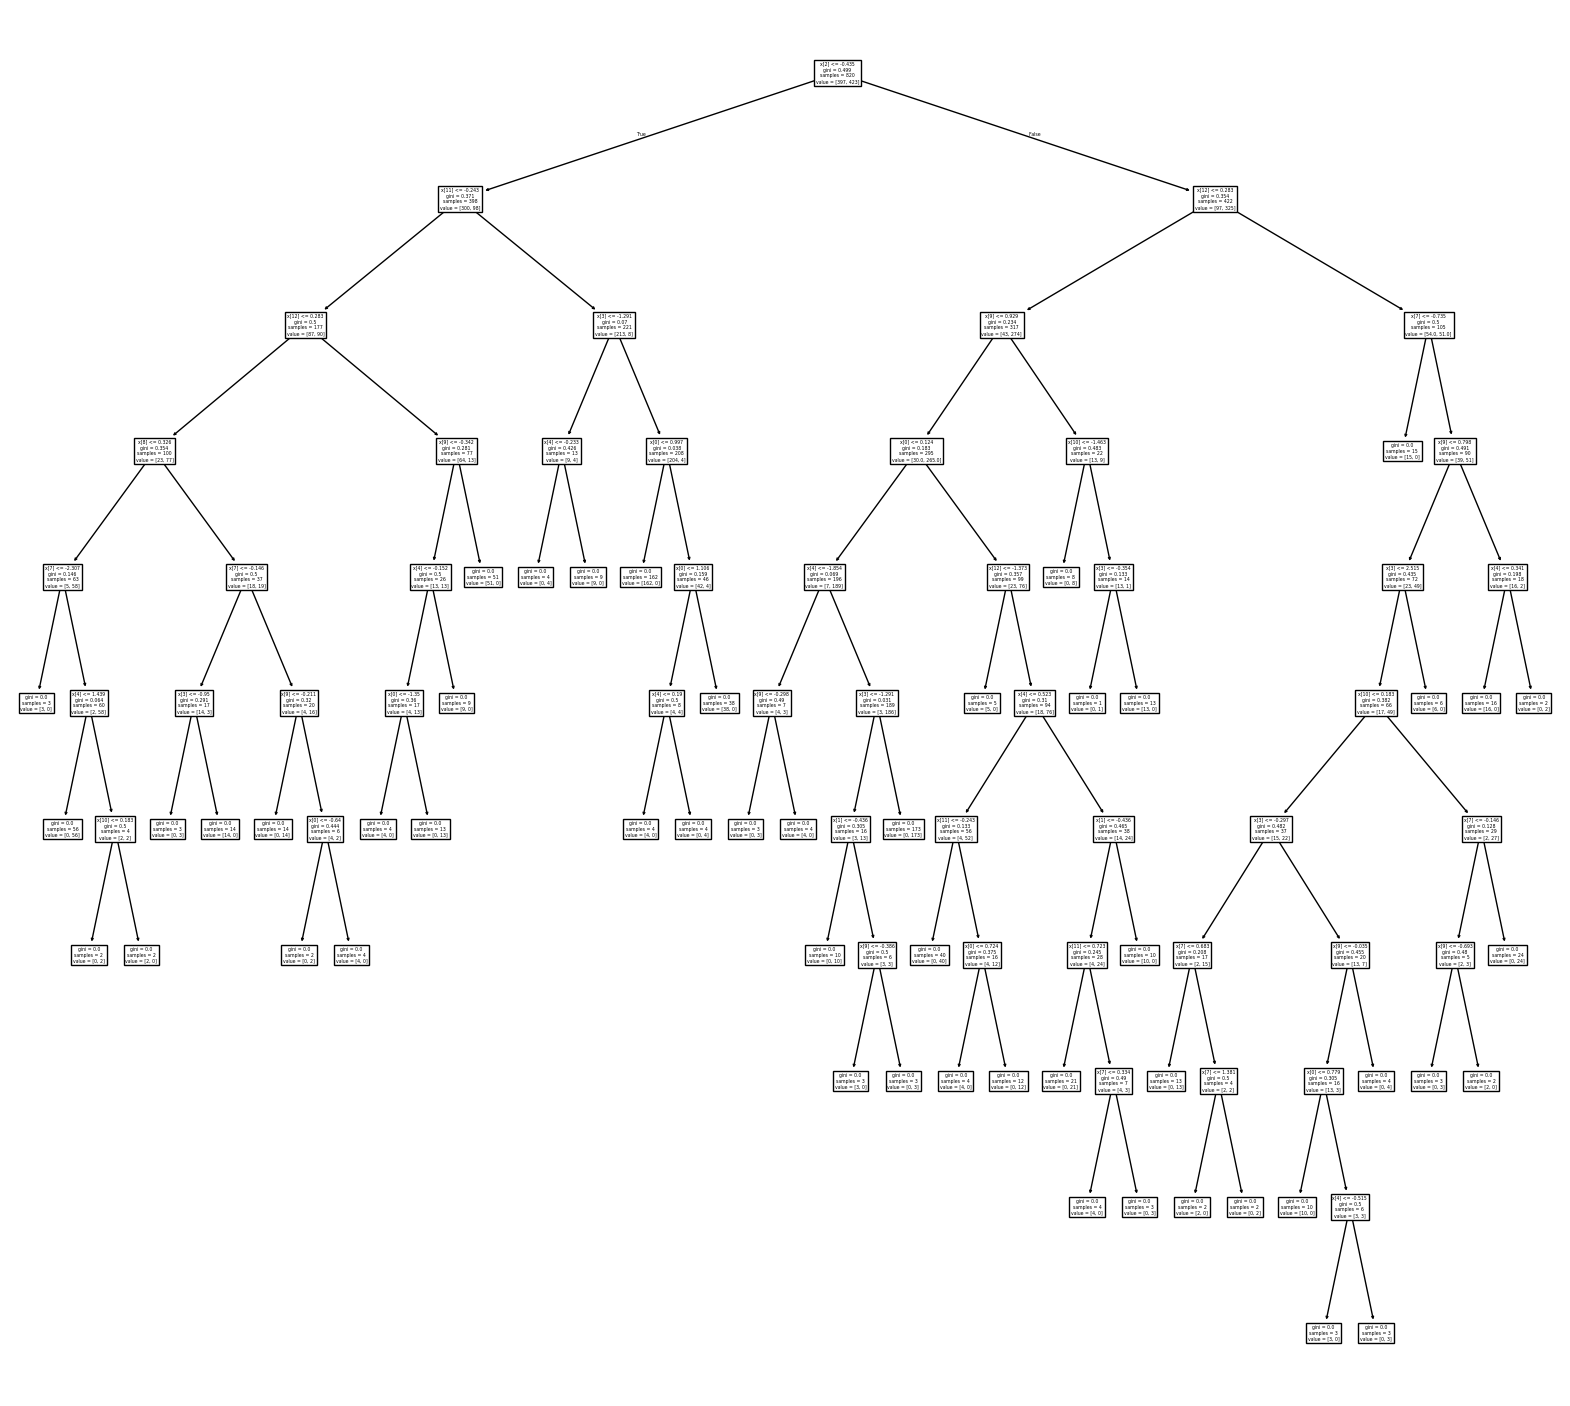

In [43]:
plt.figure(figsize=(20,18))
tree.plot_tree(tree_gini) 

In [44]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [45]:
feature_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
class_names = ["No Disease", "Disease"]

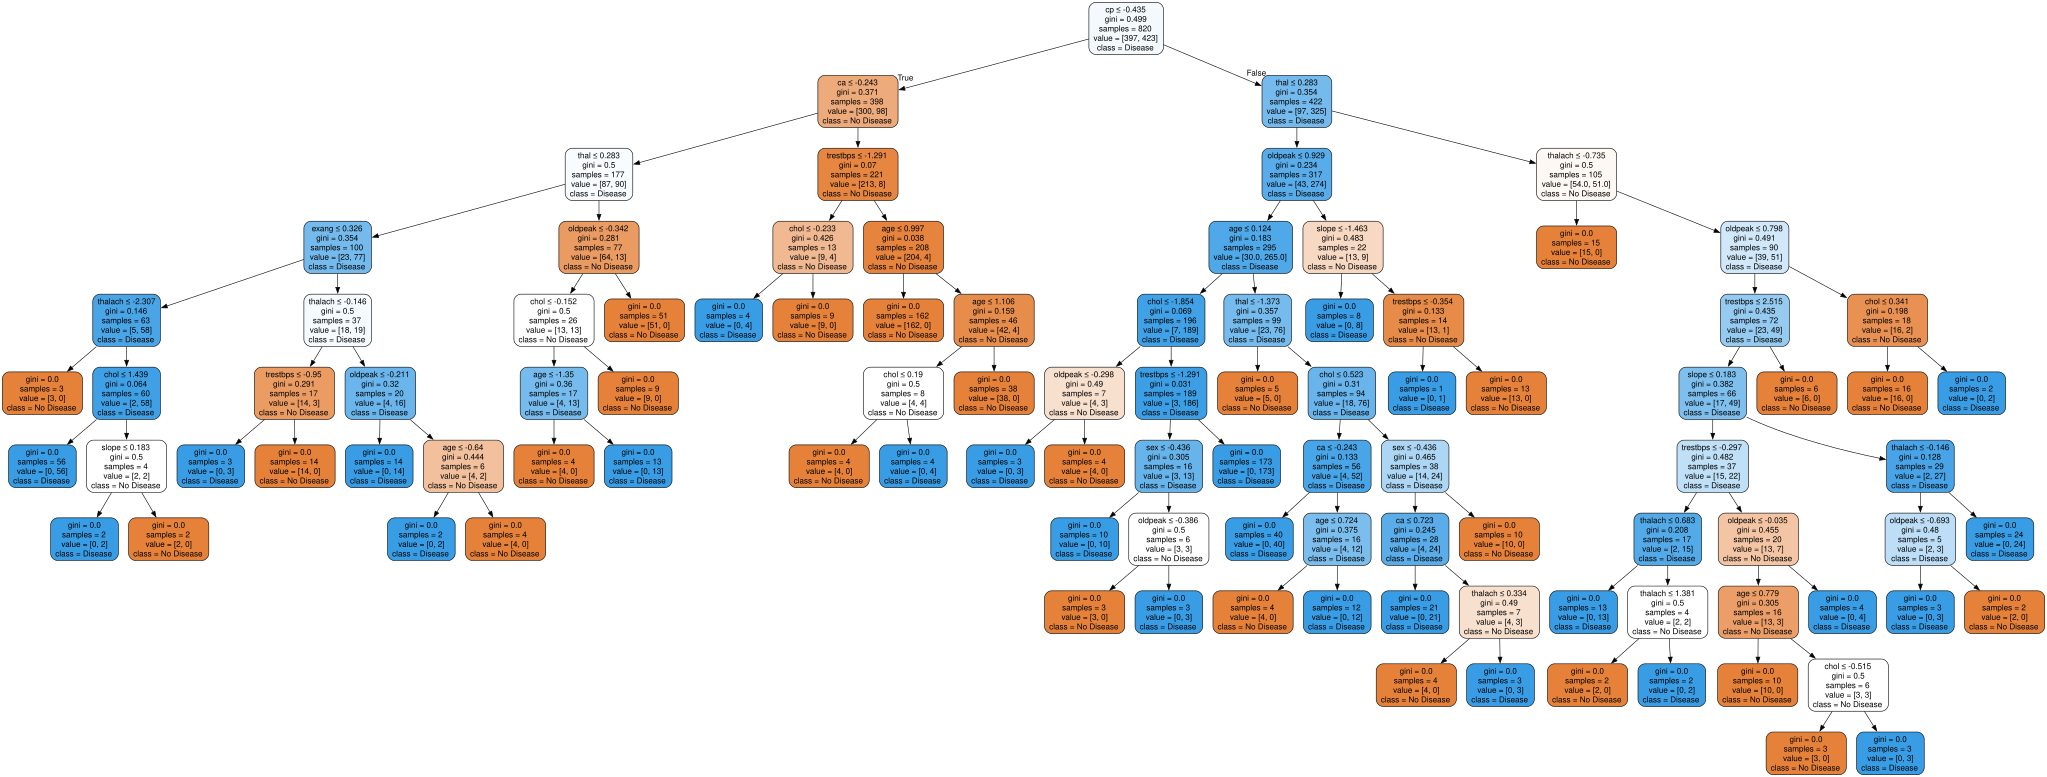

In [46]:
dot_data = tree.export_graphviz(tree_gini, out_file=None, 
                              feature_names=feature_names,  
                              class_names=class_names,  
                              filled=True, rounded=True,  
                              special_characters=True)

graph = graphviz.Source(dot_data)
graph 

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.68      0.75       102
           1       0.73      0.88      0.80       103

    accuracy                           0.78       205
   macro avg       0.79      0.78      0.78       205
weighted avg       0.79      0.78      0.78       205

------------------------------------------


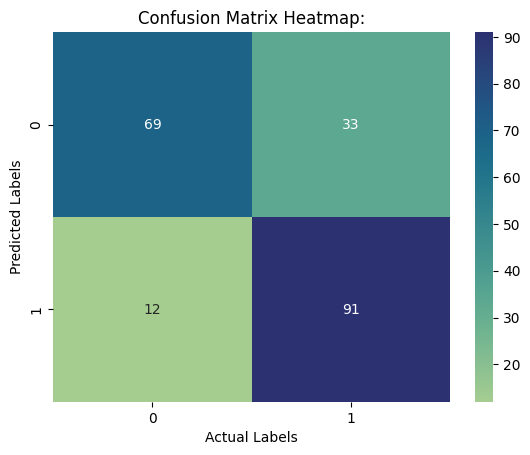

AUC-ROC Score: 0.8202


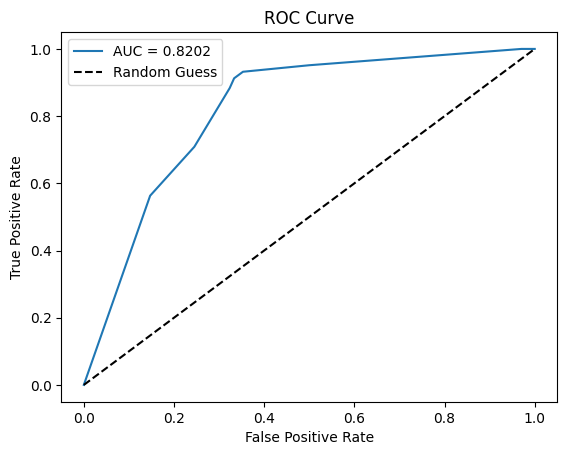

In [51]:
tree_gini_2 = DecisionTreeClassifier(criterion='gini', max_depth=3).fit(X_train, y_train)
evolution_models(tree_gini_2)

[Text(0.5, 0.875, 'x[2] <= -0.435\ngini = 0.499\nsamples = 820\nvalue = [397, 423]'),
 Text(0.25, 0.625, 'x[11] <= -0.243\ngini = 0.371\nsamples = 398\nvalue = [300, 98]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'x[12] <= 0.283\ngini = 0.5\nsamples = 177\nvalue = [87, 90]'),
 Text(0.0625, 0.125, 'gini = 0.354\nsamples = 100\nvalue = [23, 77]'),
 Text(0.1875, 0.125, 'gini = 0.281\nsamples = 77\nvalue = [64, 13]'),
 Text(0.375, 0.375, 'x[3] <= -1.291\ngini = 0.07\nsamples = 221\nvalue = [213, 8]'),
 Text(0.3125, 0.125, 'gini = 0.426\nsamples = 13\nvalue = [9, 4]'),
 Text(0.4375, 0.125, 'gini = 0.038\nsamples = 208\nvalue = [204, 4]'),
 Text(0.75, 0.625, 'x[12] <= 0.283\ngini = 0.354\nsamples = 422\nvalue = [97, 325]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'x[9] <= 0.929\ngini = 0.234\nsamples = 317\nvalue = [43, 274]'),
 Text(0.5625, 0.125, 'gini = 0.183\nsamples = 295\nvalue = [30.0, 265.0]'),
 Text(0.6875, 0.125, 'gini = 0.483\nsamples = 22\nvalue = [13, 9]'),


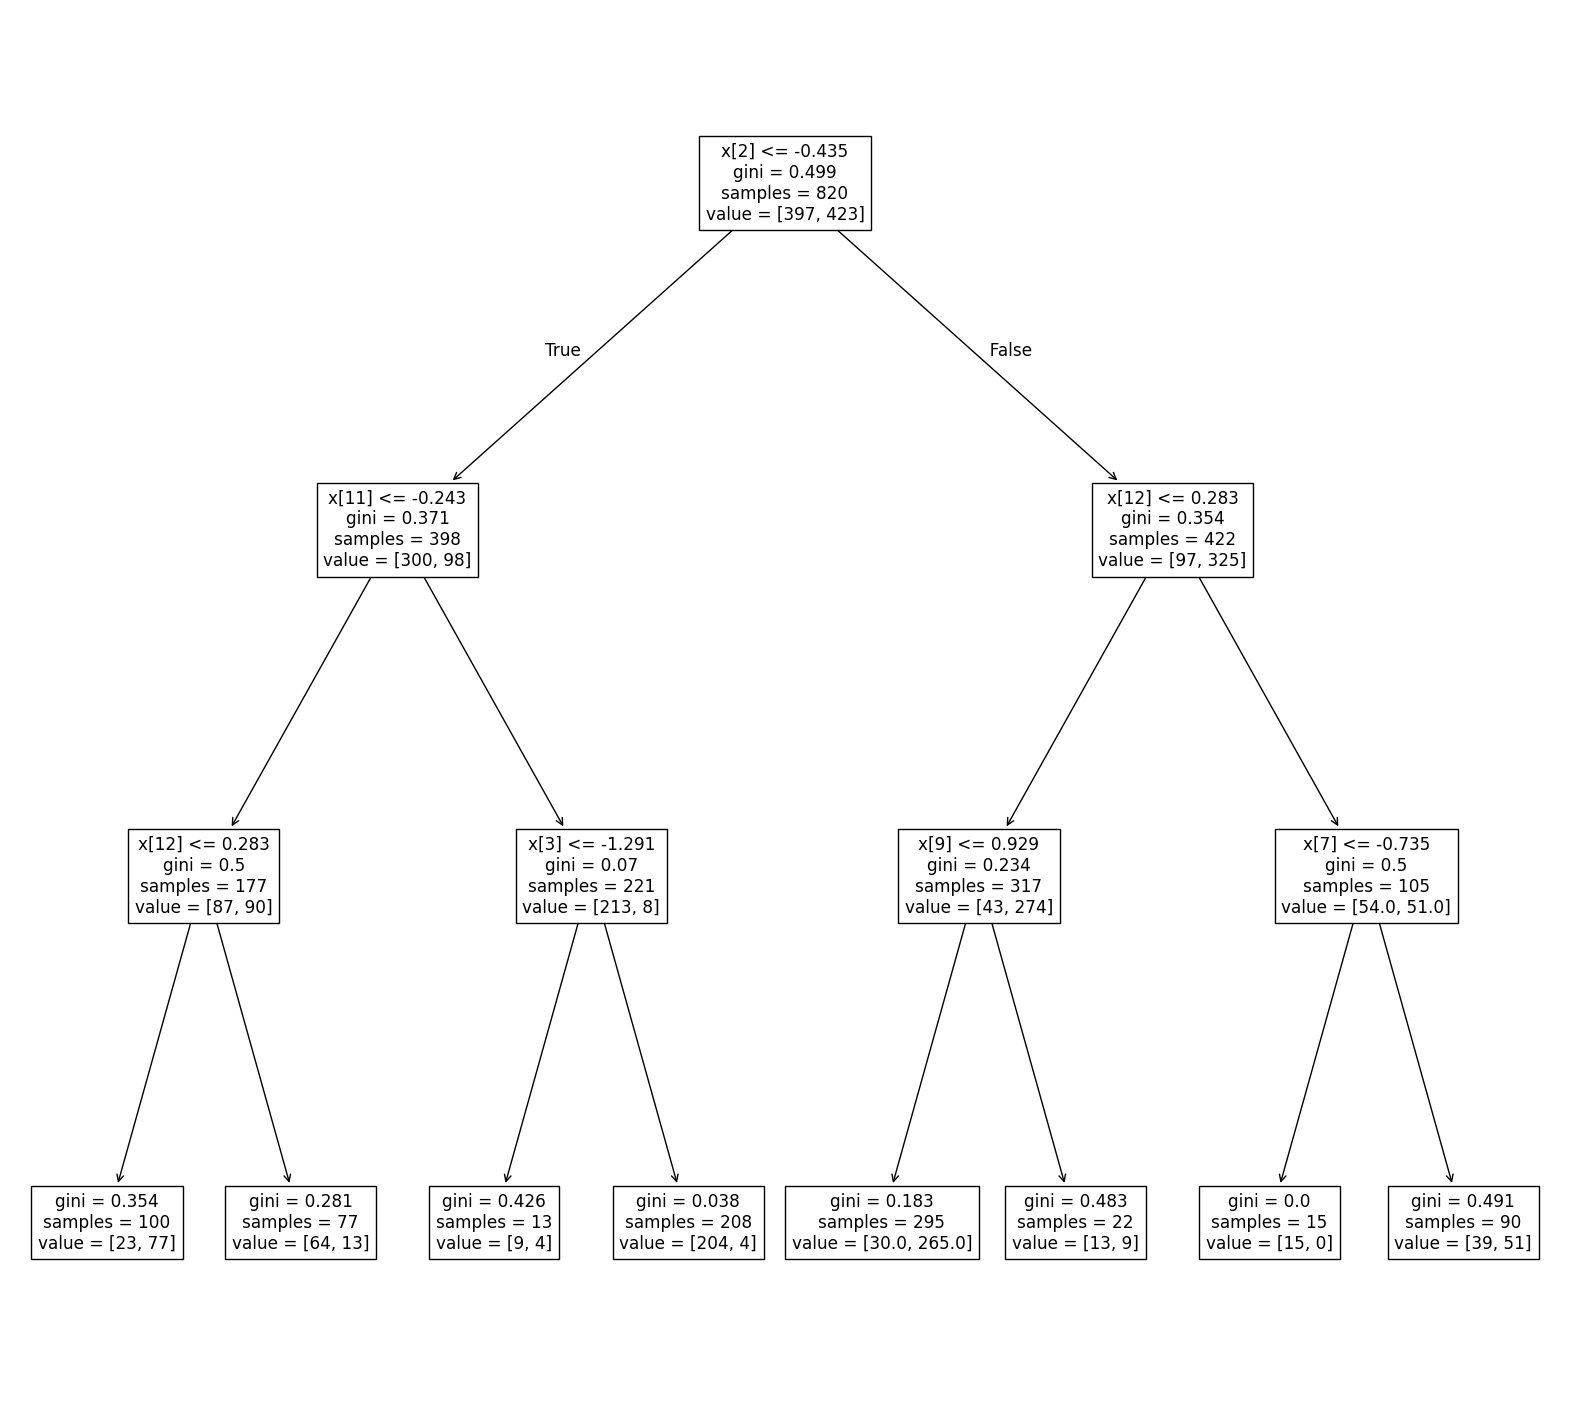

In [53]:
plt.figure(figsize=(20,18))
tree.plot_tree(tree_gini_2) 

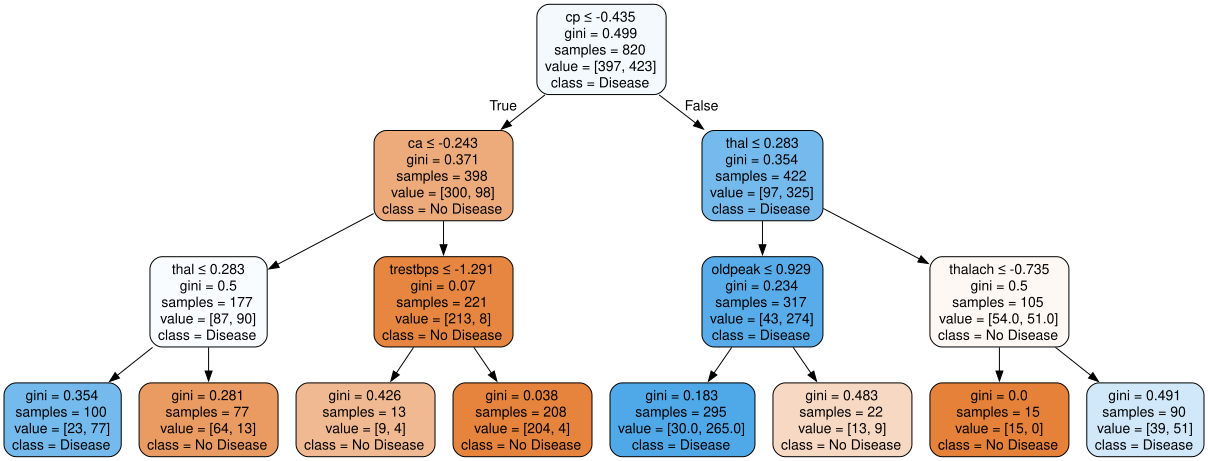

In [54]:
dot_data = tree.export_graphviz(tree_gini_2, out_file=None, 
                              feature_names=feature_names,  
                              class_names=class_names,  
                              filled=True, rounded=True,  
                              special_characters=True)

graph = graphviz.Source(dot_data)
graph 

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters found: {'max_depth': 10, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best mean cross-validation accuracy: 98.29 %

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

------------------------------------------


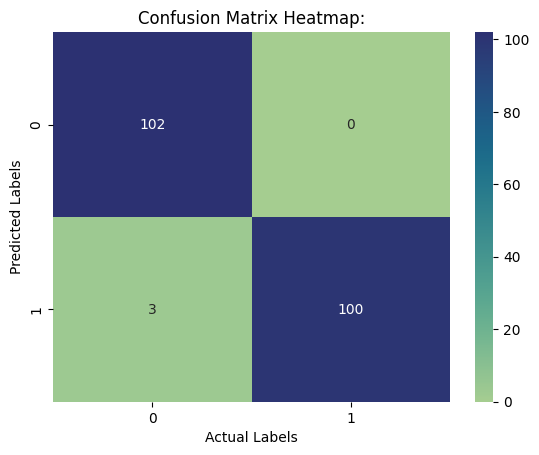

AUC-ROC Score: 0.9854


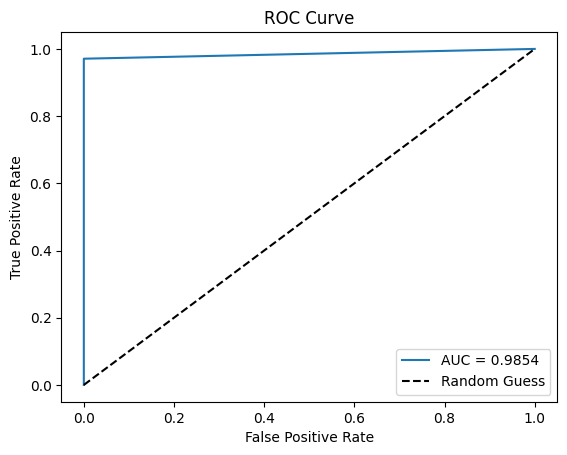

In [57]:
gr_gini = DecisionTreeClassifier(criterion='gini')

param_grid = {
    'max_depth': [3, 5, 10, None],  # Limit the depth of the tree to avoid overfitting.
    'min_samples_split': [2, 5, 10],  # Minimum number of samples to split the node
    'min_samples_leaf': [1, 2, 4],  # Minimum number of samples per leaf
    'max_features': [None, 'sqrt', 'log2']  # These characteristics are considered when finding the best way to divide
}

best_gini = Gridsearch_params(X_train, y_train, gr_gini, param_grid)
evolution_models(best_gini)

In [59]:
import joblib
joblib.dump(best_gini, 'best_gini_model.pkl')

# To load the model later
loaded_model = joblib.load('best_gini_model.pkl')

[Text(0.5315126050420168, 0.9545454545454546, 'x[2] <= -0.435\ngini = 0.499\nsamples = 820\nvalue = [397, 423]'),
 Text(0.28781512605042014, 0.8636363636363636, 'x[11] <= -0.243\ngini = 0.371\nsamples = 398\nvalue = [300, 98]'),
 Text(0.4096638655462185, 0.9090909090909092, 'True  '),
 Text(0.18907563025210083, 0.7727272727272727, 'x[12] <= 0.283\ngini = 0.5\nsamples = 177\nvalue = [87, 90]'),
 Text(0.09243697478991597, 0.6818181818181818, 'x[8] <= 0.326\ngini = 0.354\nsamples = 100\nvalue = [23, 77]'),
 Text(0.03361344537815126, 0.5909090909090909, 'x[7] <= -2.307\ngini = 0.146\nsamples = 63\nvalue = [5, 58]'),
 Text(0.01680672268907563, 0.5, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.05042016806722689, 0.5, 'x[4] <= 1.439\ngini = 0.064\nsamples = 60\nvalue = [2, 58]'),
 Text(0.03361344537815126, 0.4090909090909091, 'gini = 0.0\nsamples = 56\nvalue = [0, 56]'),
 Text(0.06722689075630252, 0.4090909090909091, 'x[9] <= -0.386\ngini = 0.5\nsamples = 4\nvalue = [2, 2]'),
 Text(0.0

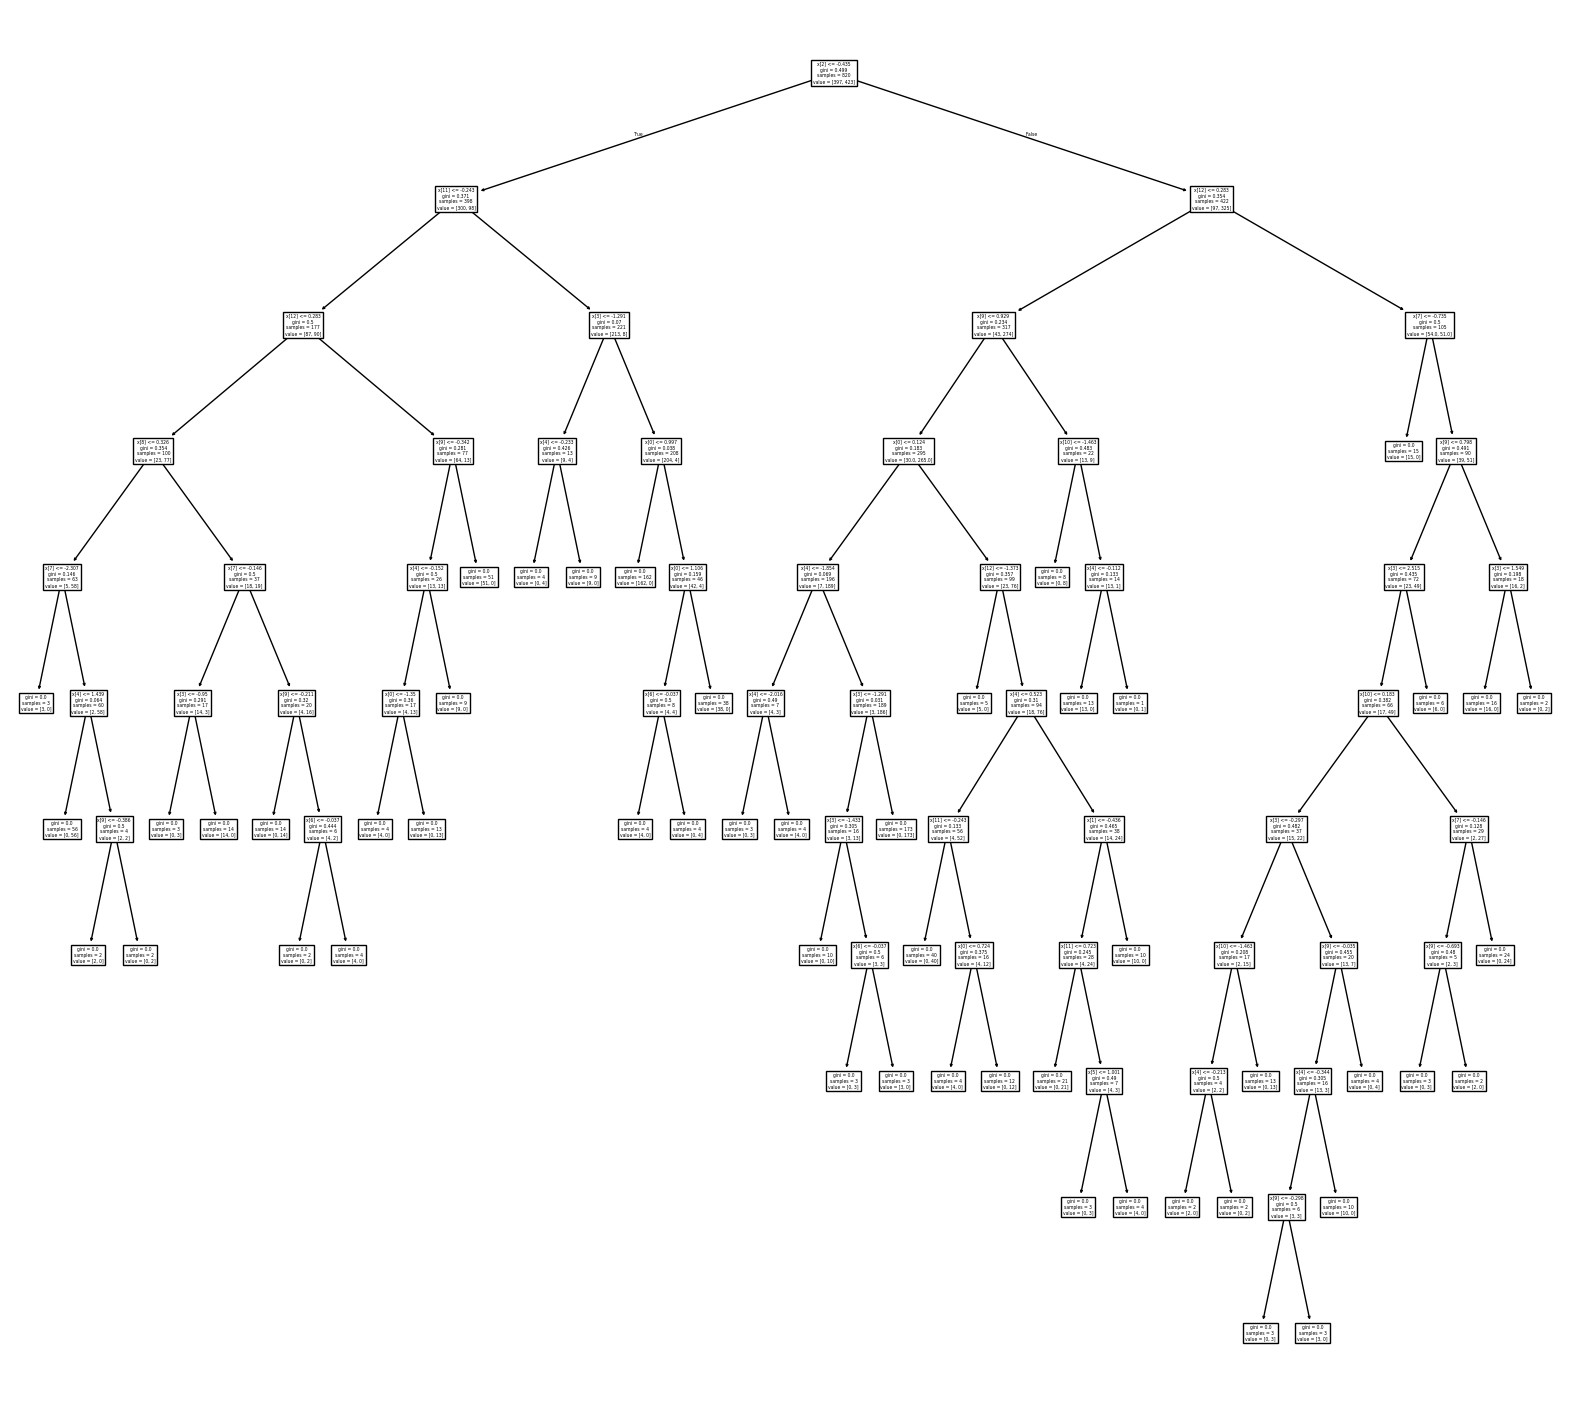

In [61]:
plt.figure(figsize=(20,18))
tree.plot_tree(best_gini) 

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

------------------------------------------


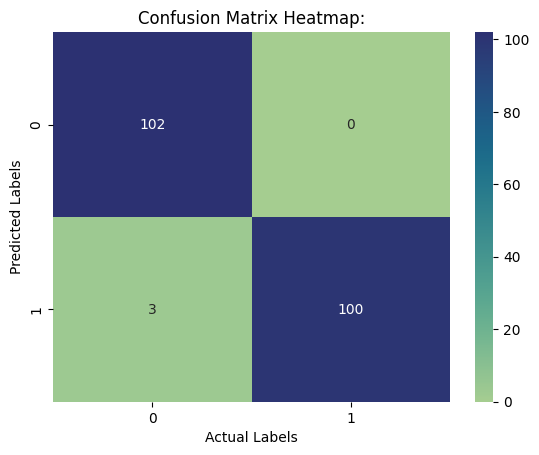

AUC-ROC Score: 0.9854


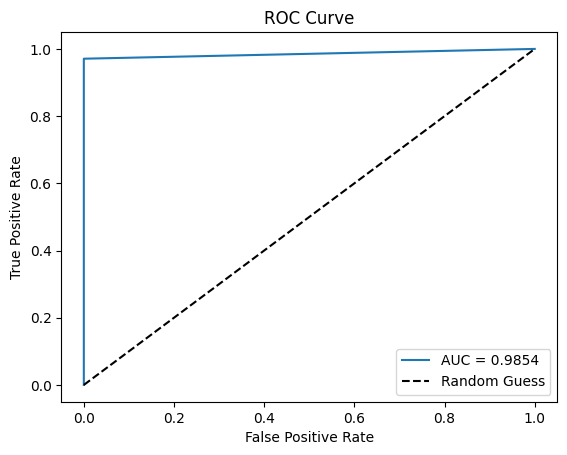

In [62]:
entropy_tree = DecisionTreeClassifier(criterion='entropy').fit(X_train, y_train)
evolution_models(entropy_tree)

[Text(0.5232142857142857, 0.9545454545454546, 'x[2] <= -0.435\nentropy = 0.999\nsamples = 820\nvalue = [397, 423]'),
 Text(0.2761904761904762, 0.8636363636363636, 'x[11] <= -0.243\nentropy = 0.805\nsamples = 398\nvalue = [300, 98]'),
 Text(0.399702380952381, 0.9090909090909092, 'True  '),
 Text(0.19047619047619047, 0.7727272727272727, 'x[12] <= 0.283\nentropy = 1.0\nsamples = 177\nvalue = [87, 90]'),
 Text(0.09523809523809523, 0.6818181818181818, 'x[8] <= 0.326\nentropy = 0.778\nsamples = 100\nvalue = [23, 77]'),
 Text(0.0380952380952381, 0.5909090909090909, 'x[7] <= -2.307\nentropy = 0.4\nsamples = 63\nvalue = [5, 58]'),
 Text(0.01904761904761905, 0.5, 'entropy = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.05714285714285714, 0.5, 'x[4] <= 1.439\nentropy = 0.211\nsamples = 60\nvalue = [2, 58]'),
 Text(0.0380952380952381, 0.4090909090909091, 'entropy = 0.0\nsamples = 56\nvalue = [0, 56]'),
 Text(0.0761904761904762, 0.4090909090909091, 'x[0] <= 0.779\nentropy = 1.0\nsamples = 4\nvalue = 

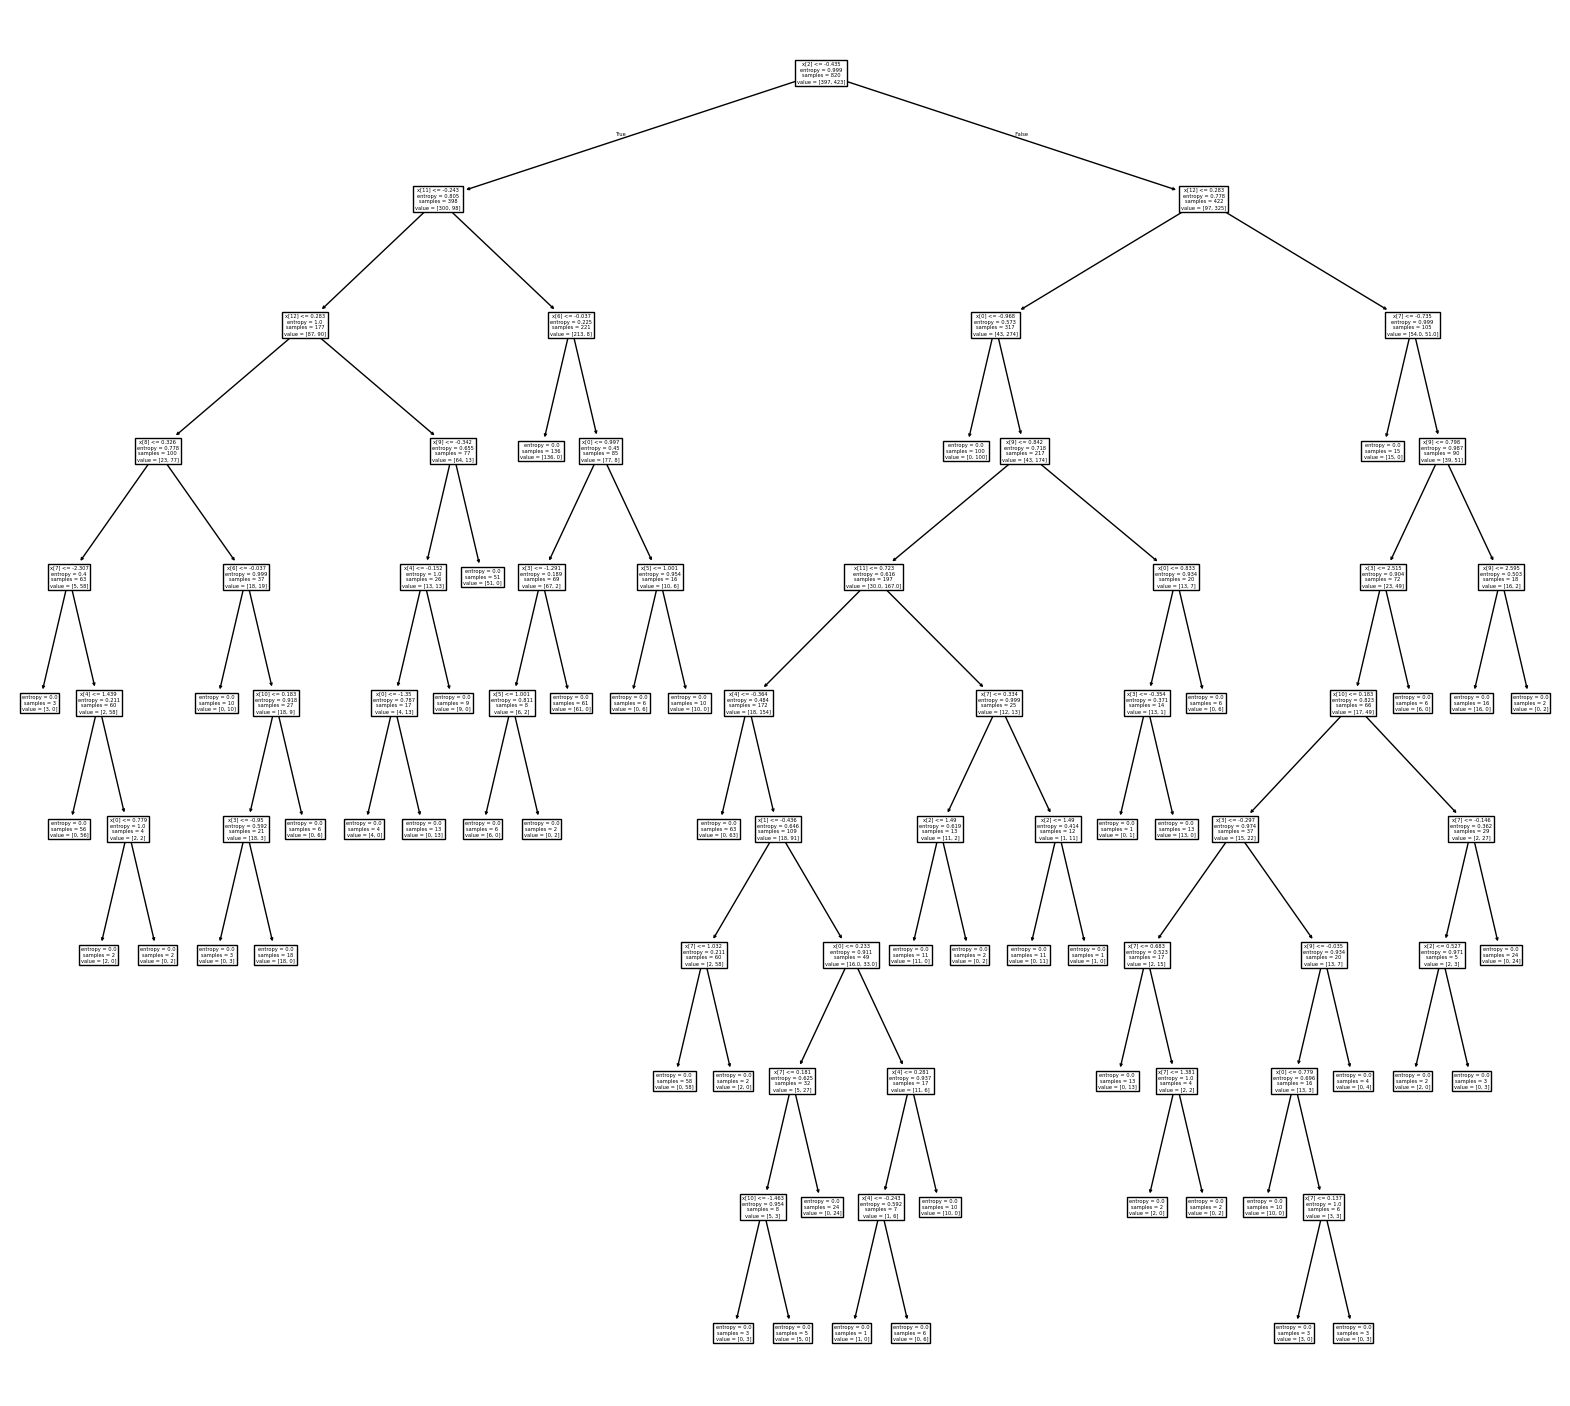

In [65]:
plt.figure(figsize=(20,18))
tree.plot_tree(entropy_tree) 

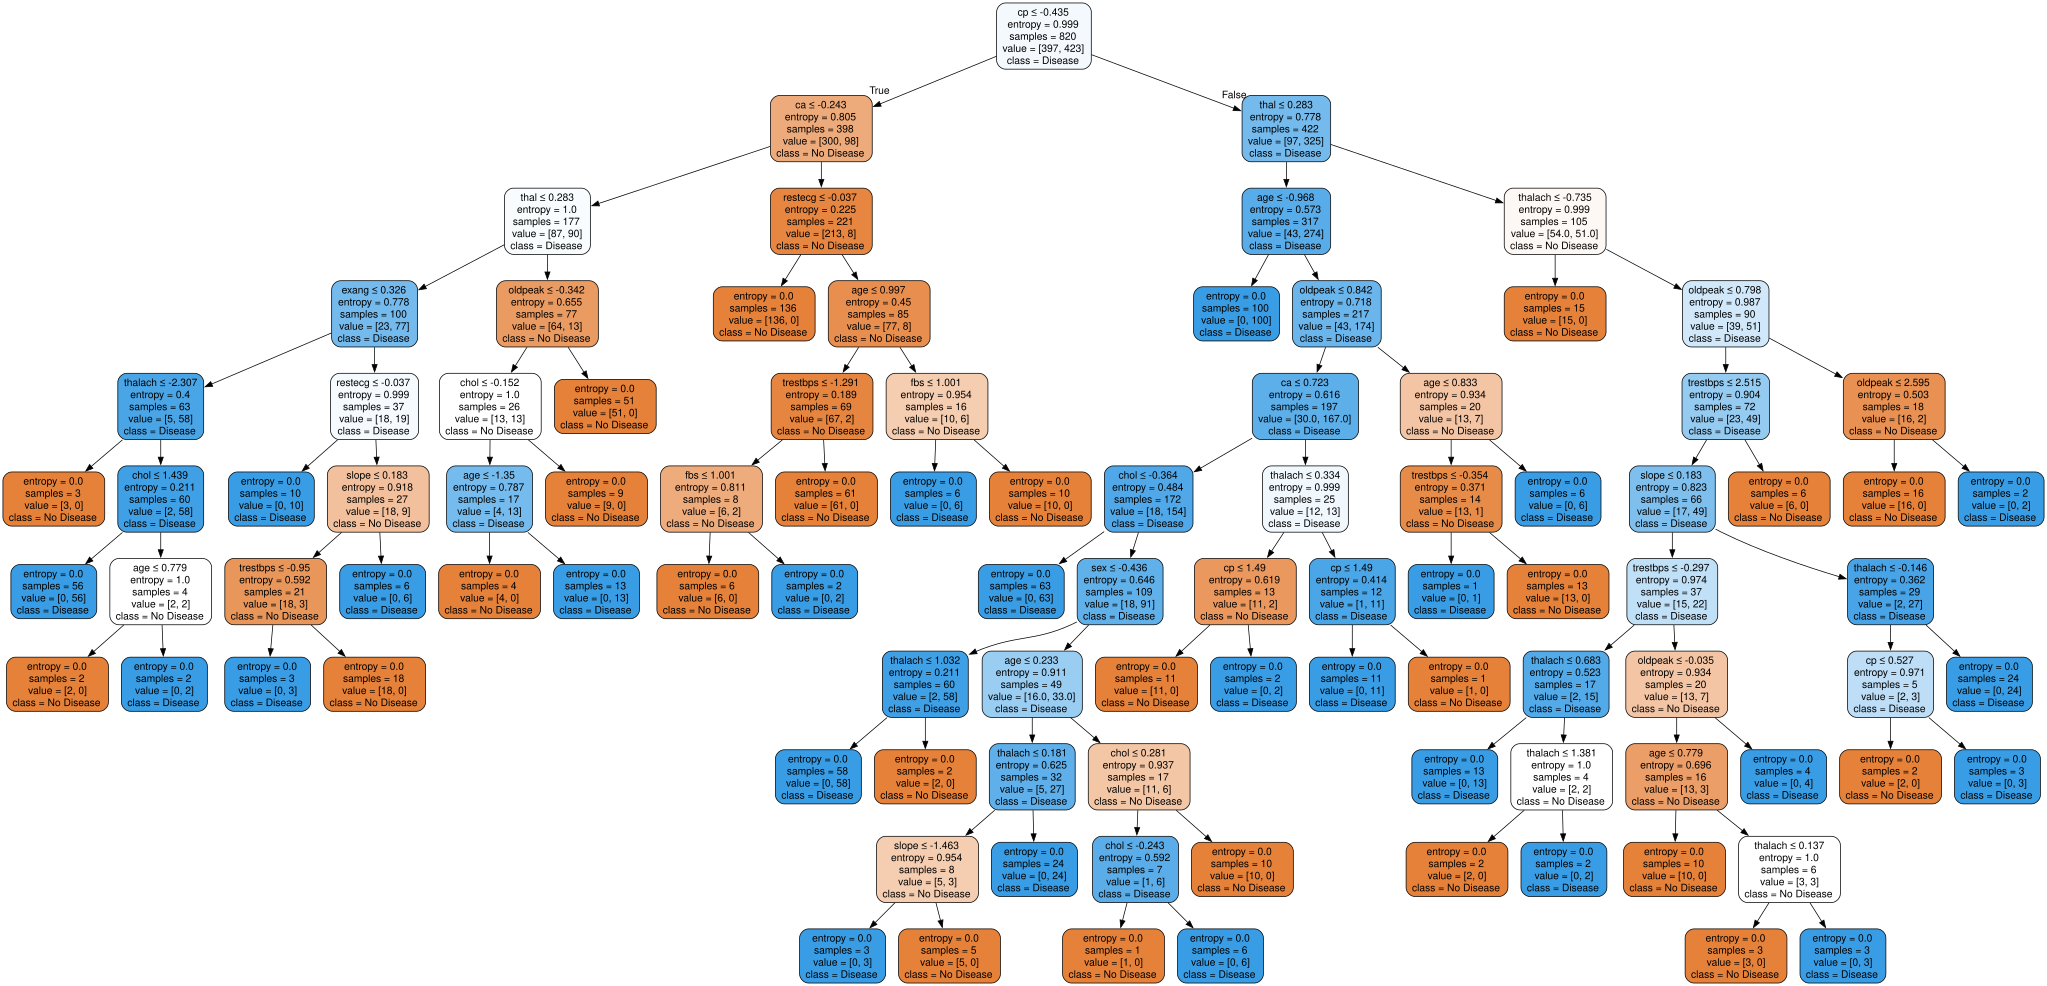

In [66]:
dot_data = tree.export_graphviz(entropy_tree, out_file=None, 
                              feature_names=feature_names,  
                              class_names=class_names,  
                              filled=True, rounded=True,  
                              special_characters=True)

graph = graphviz.Source(dot_data)
graph 

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters found: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
Best mean cross-validation accuracy: 97.68 %

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

------------------------------------------


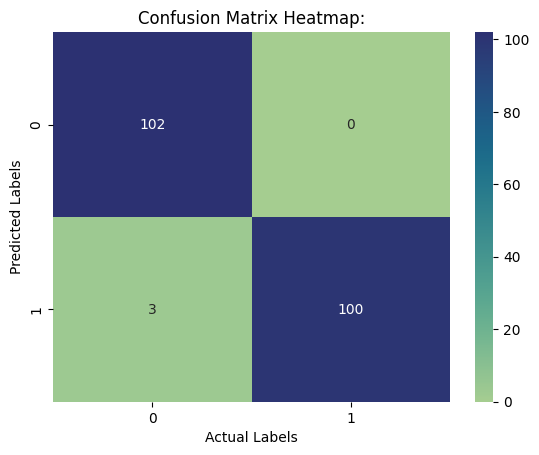

AUC-ROC Score: 0.9854


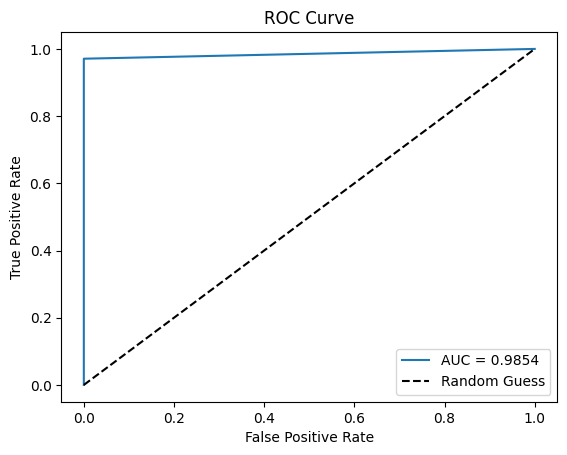

In [67]:
gr_entropy = DecisionTreeClassifier(criterion='entropy')

param_grid = {
    'max_depth': [3, 5, 10, None],  # Limit the depth of the tree to avoid overfitting.
    'min_samples_split': [2, 5, 10],  # Minimum number of samples to split the node
    'min_samples_leaf': [1, 2, 4],  # Minimum number of samples per leaf
    'max_features': [None, 'sqrt', 'log2']  # These characteristics are considered when finding the best way to divide
}

best_entropy = Gridsearch_params(X_train, y_train, gr_entropy, param_grid)
evolution_models(best_entropy)

In [68]:
import pickle

# Save the model
with open('best_entropy_model.pkl', 'wb') as file:
    pickle.dump(best_entropy, file)

# Later, to load the model
with open('best_entropy_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)


Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

------------------------------------------


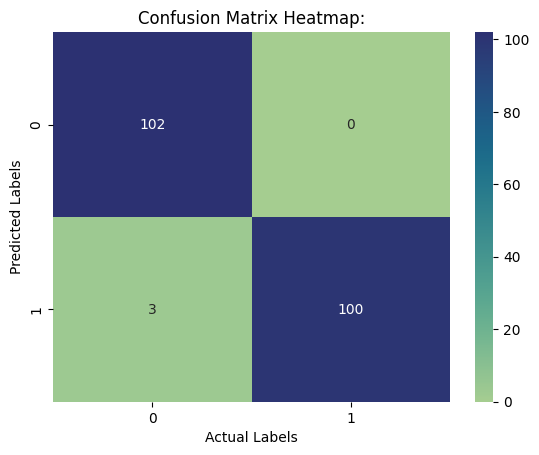

AUC-ROC Score: 0.9991


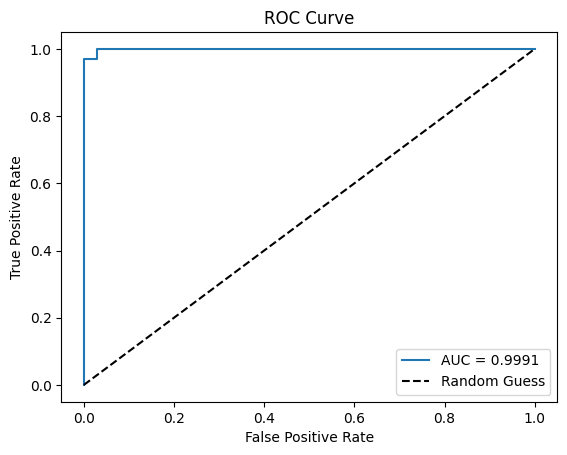

In [71]:
rf_tree = RandomForestClassifier().fit(X_train, y_train)
evolution_models(rf_tree)

In [ ]:
rf_base = RandomForestClassifier()
param_grid = {
    'n_estimators': [50, 100, 200], 
    'max_depth': [10, 20, 30, None], 
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'criterion': ['entropy', 'gini']
}
best_rf = Gridsearch_params(X_train, y_train, rf_base, param_grid)
evolution_models(best_rf)

Fitting 5 folds for each of 648 candidates, totalling 3240 fits


In [ ]:
#logistic regression

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
# Hyperparameter tuning with GridSearchCV
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2', 'elasticnet', 'none'],
    'solver': ['liblinear', 'saga'],
    'max_iter': [100, 200, 500]
}

In [ ]:
logistic_model = LogisticRegression(random_state=42)
grid_search = GridSearchCV(logistic_model, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

In [ ]:
# Best parameters and model
best_model = grid_search.best_estimator_
print("Best Parameters:")
print(grid_search.best_params_)

In [ ]:
evolution_models(best_model)

In [ ]:
#hp with pso algorithm

In [ ]:
from pyswarm import pso

In [88]:
# Define objective function for PSO
def objective_function(params):
    C, max_iter = params
    try:
        model = LogisticRegression(C=C, max_iter=int(max_iter), solver='liblinear', random_state=42)
        model.fit(X_train, y_train)
        y_prob = model.predict_proba(X_test)[:, 1]
        return -roc_auc_score(y_test, y_prob)  # Negative AUC for minimization
    except Exception:
        return float('inf')

In [90]:
# Bounds for parameters
lb = [0.01, 50]  # Lower bounds for C and max_iter
ub = [100, 500]  # Upper bounds for C and max_iter

In [92]:
# Perform PSO optimization
best_params, _ = pso(objective_function, lb, ub, swarmsize=20, maxiter=50)

# Extract best parameters
best_C, best_max_iter = best_params


Stopping search: maximum iterations reached --> 50


In [98]:
# Extract best parameters
best_C, best_max_iter = best_params

# Train the model with optimal parameters
best_model2 = LogisticRegression(C=best_C, max_iter=int(best_max_iter), solver='liblinear', random_state=42)
best_model2.fit(X_train, y_train)
print("Best Parameters from PSO:")
print(f"C: {best_C}, max_iter: {int(best_max_iter)}")

Best Parameters from PSO:
C: 0.01, max_iter: 319


Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.69      0.76       102
           1       0.74      0.88      0.81       103

    accuracy                           0.79       205
   macro avg       0.80      0.78      0.78       205
weighted avg       0.80      0.79      0.78       205

------------------------------------------


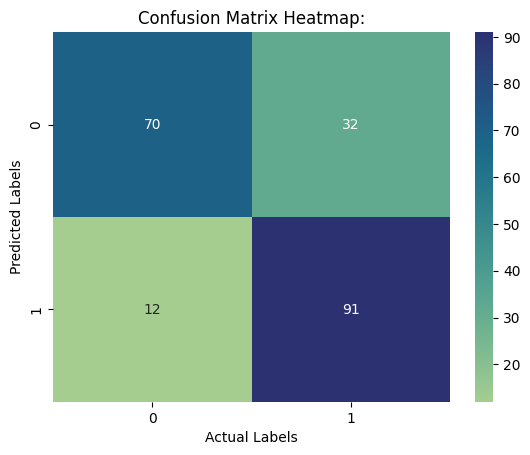

AUC-ROC Score: 0.8814


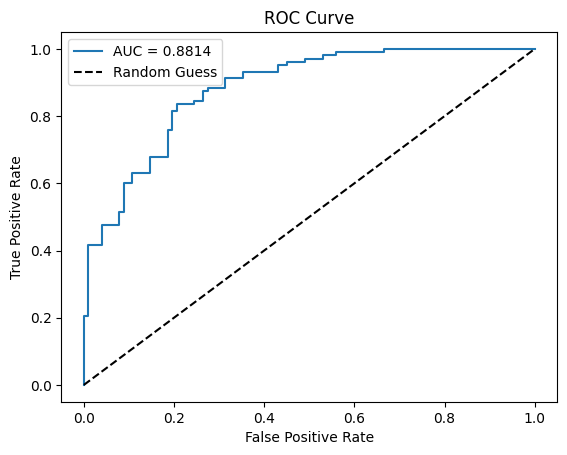

In [100]:
evolution_models(best_model2)

In [102]:
#random search 

Best Parameters from RandomizedSearchCV:
{'C': 4.676566321361543, 'max_iter': 500, 'penalty': 'l2', 'solver': 'saga'}
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.72      0.78       102
           1       0.76      0.87      0.81       103

    accuracy                           0.80       205
   macro avg       0.80      0.79      0.79       205
weighted avg       0.80      0.80      0.79       205

------------------------------------------


C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\model_selection\_validation.py:540: FitFailedWarning: 
290 fits failed out of a total of 500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
60 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\INFINITYv\myproject\myenv\Lib\site-packages\sklearn\linear_model\_logi

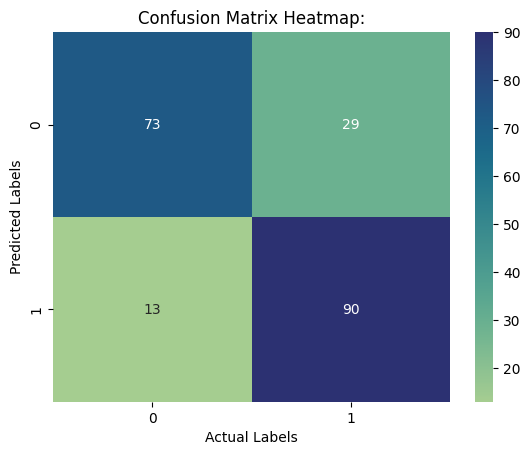

AUC-ROC Score: 0.8780


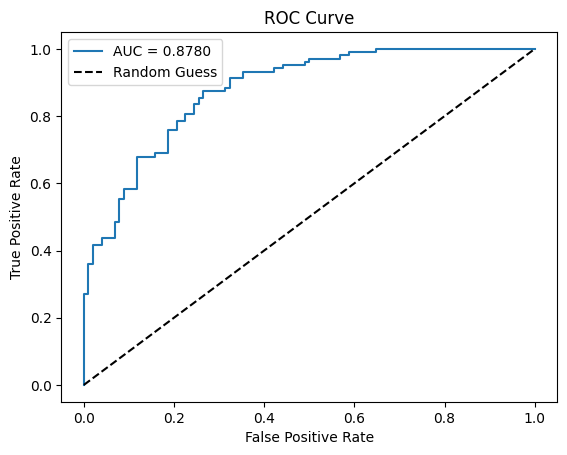

In [110]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform

# Hyperparameter distribution
param_dist = {
    'C': uniform(0.01, 100),
    'penalty': ['l1', 'l2', 'elasticnet', 'none'],
    'solver': ['liblinear', 'saga'],
    'max_iter': [100, 200, 500]
}

# Random Search for hyperparameter tuning
random_search = RandomizedSearchCV(logistic_model, param_dist, n_iter=100, cv=5, scoring='roc_auc', n_jobs=-1, random_state=42)
random_search.fit(X_train, y_train)

# Best model and parameters
best_model = random_search.best_estimator_
print("Best Parameters from RandomizedSearchCV:")
print(random_search.best_params_)

# Call your evolution_models function here
evolution_models(best_model)


## Logistic Regression


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters found: {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
Best mean cross-validation accuracy: 85.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.72      0.78       102
           1       0.76      0.87      0.81       103

    accuracy                           0.80       205
   macro avg       0.80      0.79      0.79       205
weighted avg       0.80      0.80      0.79       205

------------------------------------------


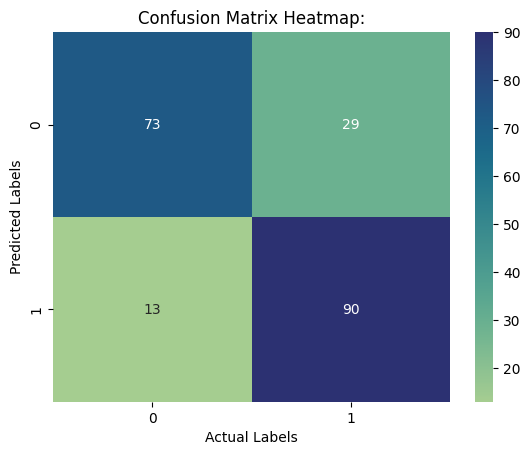

AUC-ROC Score: 0.8783


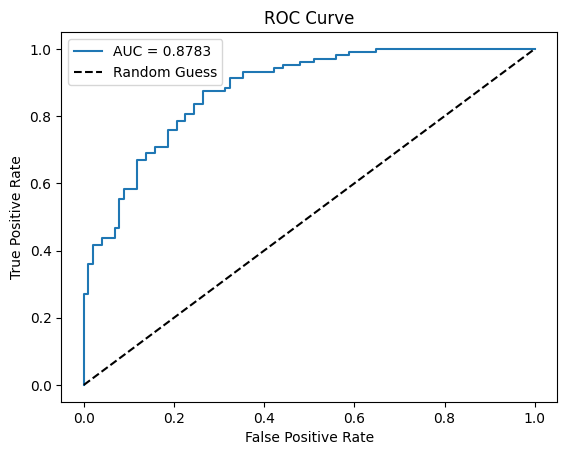

In [41]:
from sklearn.linear_model import LogisticRegression
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10], 
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga']
}

# Train Logistic Regression with Grid Search
logistic_model = Gridsearch_params(X_train, y_train, LogisticRegression(), param_grid)

# Evaluate the best model
evolution_models(logistic_model)

Fitting 10 folds for each of 72 candidates, totalling 720 fits
Best Parameters Found: {'C': 1, 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'saga'}
Best Cross-Validation Accuracy: 86.22%

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.74      0.79       102
           1       0.77      0.86      0.81       103

    accuracy                           0.80       205
   macro avg       0.80      0.80      0.80       205
weighted avg       0.80      0.80      0.80       205



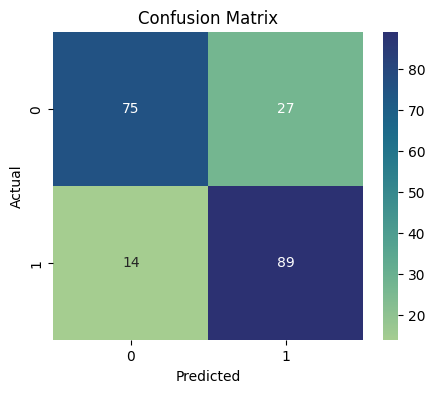

AUC-ROC Score: 0.8786


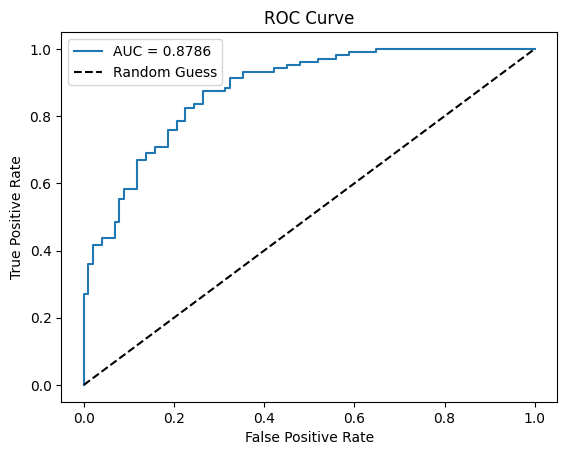

In [43]:
# Import necessary libraries
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import seaborn as sns
import matplotlib.pyplot as plt

# Standardizing the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define hyperparameter grid for Logistic Regression
param_grid = {
    'C': [0.0001, 0.001, 0.01, 0.1, 1, 5, 10, 50, 100],  
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'class_weight': ['balanced', None]
}

# Perform Grid Search
grid_search = GridSearchCV(
    estimator=LogisticRegression(),
    param_grid=param_grid,
    cv=10,  
    scoring='accuracy',  
    verbose=1,  
    n_jobs=-1  
)

grid_search.fit(X_train_scaled, y_train)

# Get best model and parameters
best_logistic = grid_search.best_estimator_
best_params = grid_search.best_params_
best_accuracy = round(grid_search.best_score_ * 100, 2)

# Evaluate the best model
y_pred = best_logistic.predict(X_test_scaled)
y_prob = best_logistic.predict_proba(X_test_scaled)[:, 1]

# Print results
print("Best Parameters Found:", best_params)
print(f"Best Cross-Validation Accuracy: {best_accuracy}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred))

# Confusion Matrix
plt.figure(figsize=(5,4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="crest", xticklabels=[0,1], yticklabels=[0,1])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# AUC-ROC Score
auc_score = roc_auc_score(y_test, y_prob)
print(f"AUC-ROC Score: {auc_score:.4f}")

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


SelectKBest: Best k = 13, AUC = 0.8861
RFE: Best k = 13, AUC = 0.8861
Embedded (RandomForest): Best k = 13, AUC = 0.8861

Best Feature Selection Method Overall: SelectKBest

Best Hyperparameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best Cross-Validation AUC Score: 0.9285

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.72      0.78       102
           1       0.76      0.89      0.82       103

    accuracy                           0.80       205
   macro avg       0.81      0.80      0.80       205
weighted avg       0.81      0.80      0.80       205



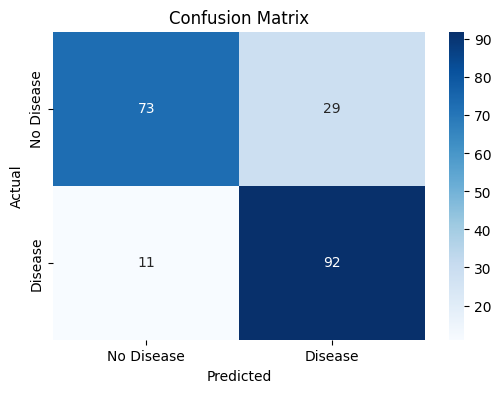

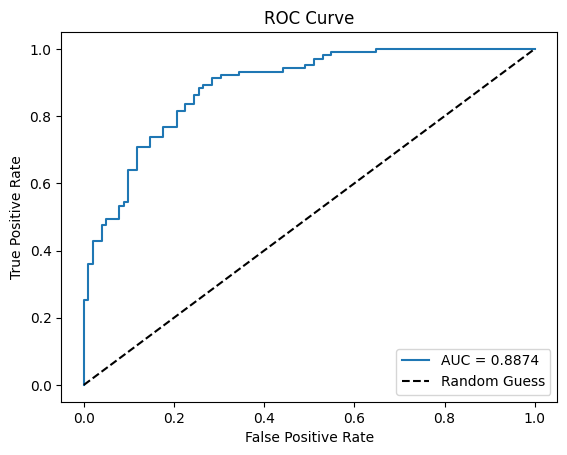

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.mstats import winsorize

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.ensemble import RandomForestClassifier

# -----------------------
# 1. Load and Preprocess Data
# -----------------------
df = pd.read_csv("heart.csv")

# Outlier Handling using Winsorization for numerical columns except the target
for col in df.columns:
    if df[col].dtype != 'object' and col != 'target':
        df[col] = winsorize(df[col], limits=[0.05, 0.05])

# -----------------------
# 2. Split and Scale Data
# -----------------------
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -----------------------
# 3. Evaluate Feature Selection Methods with Multiple k Values
# -----------------------
# We will try different numbers of features from 2 up to the total number of features.
possible_ks = range(2, X_train.shape[1] + 1)

def evaluate_selectkbest(possible_ks):
    best_auc = 0
    best_k = None
    best_X_train = None
    best_X_test = None
    for k in possible_ks:
        skb = SelectKBest(score_func=f_classif, k=k)
        X_train_new = skb.fit_transform(X_train, y_train)
        X_test_new = skb.transform(X_test)
        model = LogisticRegression(max_iter=1000, random_state=42)
        model.fit(X_train_new, y_train)
        auc = roc_auc_score(y_test, model.predict_proba(X_test_new)[:, 1])
        # Uncomment the next line to view performance for each k:
        # print(f"SelectKBest with k={k}: AUC = {auc:.4f}")
        if auc > best_auc:
            best_auc = auc
            best_k = k
            best_X_train = X_train_new
            best_X_test = X_test_new
    print(f"SelectKBest: Best k = {best_k}, AUC = {best_auc:.4f}")
    return best_k, best_auc, best_X_train, best_X_test

def evaluate_rfe(possible_ks):
    best_auc = 0
    best_k = None
    best_X_train = None
    best_X_test = None
    base_estimator = LogisticRegression(max_iter=1000, random_state=42)
    for k in possible_ks:
        rfe_selector = RFE(estimator=base_estimator, n_features_to_select=k)
        X_train_new = rfe_selector.fit_transform(X_train, y_train)
        X_test_new = rfe_selector.transform(X_test)
        model = LogisticRegression(max_iter=1000, random_state=42)
        model.fit(X_train_new, y_train)
        auc = roc_auc_score(y_test, model.predict_proba(X_test_new)[:, 1])
        # Uncomment the next line to view performance for each k:
        # print(f"RFE with k={k}: AUC = {auc:.4f}")
        if auc > best_auc:
            best_auc = auc
            best_k = k
            best_X_train = X_train_new
            best_X_test = X_test_new
    print(f"RFE: Best k = {best_k}, AUC = {best_auc:.4f}")
    return best_k, best_auc, best_X_train, best_X_test

def evaluate_embedded(possible_ks):
    best_auc = 0
    best_k = None
    best_X_train = None
    best_X_test = None
    # Fit a RandomForestClassifier to obtain feature importances.
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_train, y_train)
    # Sort feature indices by importance (descending order)
    sorted_indices = np.argsort(rf.feature_importances_)[::-1]
    for k in possible_ks:
        selected_indices = sorted_indices[:k]
        X_train_new = X_train[:, selected_indices]
        X_test_new = X_test[:, selected_indices]
        model = LogisticRegression(max_iter=1000, random_state=42)
        model.fit(X_train_new, y_train)
        auc = roc_auc_score(y_test, model.predict_proba(X_test_new)[:, 1])
        # Uncomment the next line to view performance for each k:
        # print(f"Embedded with k={k}: AUC = {auc:.4f}")
        if auc > best_auc:
            best_auc = auc
            best_k = k
            best_X_train = X_train_new
            best_X_test = X_test_new
    print(f"Embedded (RandomForest): Best k = {best_k}, AUC = {best_auc:.4f}")
    return best_k, best_auc, best_X_train, best_X_test

# Evaluate each method
kb_k, kb_auc, X_train_kb, X_test_kb = evaluate_selectkbest(possible_ks)
rfe_k, rfe_auc, X_train_rfe_best, X_test_rfe_best = evaluate_rfe(possible_ks)
emb_k, emb_auc, X_train_emb_best, X_test_emb_best = evaluate_embedded(possible_ks)

# -----------------------
# 4. Select the Best Feature Selection Method Overall
# -----------------------
if kb_auc >= rfe_auc and kb_auc >= emb_auc:
    best_method = "SelectKBest"
    X_train_best, X_test_best = X_train_kb, X_test_kb
elif rfe_auc >= kb_auc and rfe_auc >= emb_auc:
    best_method = "RFE"
    X_train_best, X_test_best = X_train_rfe_best, X_test_rfe_best
else:
    best_method = "Embedded"
    X_train_best, X_test_best = X_train_emb_best, X_test_emb_best

print(f"\nBest Feature Selection Method Overall: {best_method}")

# -----------------------
# 5. Hyperparameter Tuning with GridSearchCV for Logistic Regression
# -----------------------
# Define hyperparameter grid for Logistic Regression
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']  # 'liblinear' supports both 'l1' and 'l2'
}

grid_search = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                           param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train_best, y_train)
print("\nBest Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation AUC Score: {:.4f}".format(grid_search.best_score_))

# The final tuned model
final_model = grid_search.best_estimator_

# -----------------------
# 6. Evaluate Final Model on Test Set
# -----------------------
y_pred_final = final_model.predict(X_test_best)
y_prob_final = final_model.predict_proba(X_test_best)[:, 1]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve
auc_final = roc_auc_score(y_test, y_prob_final)
fpr, tpr, _ = roc_curve(y_test, y_prob_final)
plt.plot(fpr, tpr, label=f"AUC = {auc_final:.4f}")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


Best Parameters: {'clf__C': 1, 'clf__penalty': 'l2', 'clf__solver': 'liblinear', 'poly__degree': 3}
Best Cross-Validation ROC-AUC: 0.9895
Test ROC-AUC: 0.9926

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205



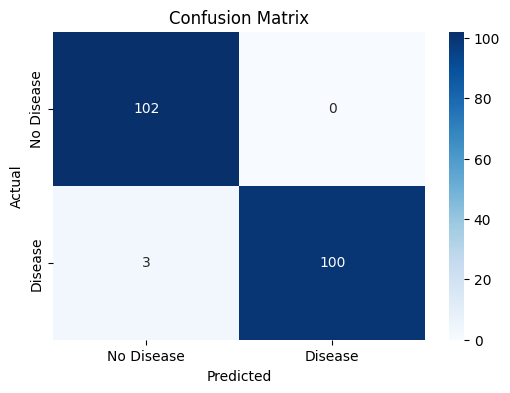

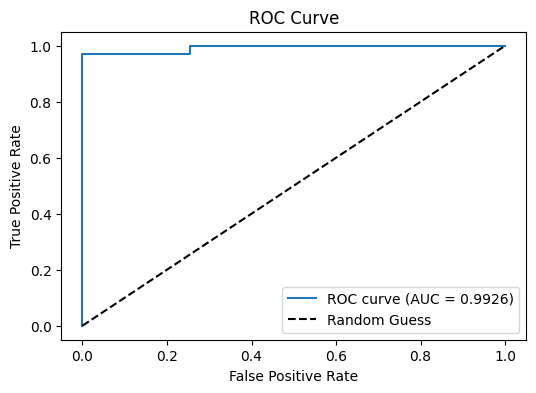

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.mstats import winsorize

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# -----------------------
# 1. Load and Preprocess Data
# -----------------------
df = pd.read_csv("heart.csv")

# Apply Winsorization to numerical features (except target) to reduce the effect of outliers
for col in df.columns:
    if df[col].dtype != 'object' and col != 'target':
        df[col] = winsorize(df[col], limits=[0.05, 0.05])

X = df.drop(columns=['target'])
y = df['target']

# -----------------------
# 2. Split Data
# -----------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------
# 3. Build a Pipeline with Polynomial Features and Logistic Regression
# -----------------------
# The pipeline includes:
#   - StandardScaler: Standardizes the features.
#   - PolynomialFeatures: Expands the feature space (try degree 1, 2, 3).
#   - LogisticRegression: Performs the classification.
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures()),  # Default: degree=2; we'll tune this.
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# -----------------------
# 4. Hyperparameter Tuning via GridSearchCV
# -----------------------
# We search over polynomial degree and logistic regression hyperparameters.
param_grid = {
    'poly__degree': [1, 2, 3],  # degree=1 is equivalent to no polynomial expansion.
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'clf__penalty': ['l1', 'l2'],
    'clf__solver': ['liblinear']  # 'liblinear' supports both l1 and l2 penalties.
}

grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation ROC-AUC: {:.4f}".format(grid_search.best_score_))

best_model = grid_search.best_estimator_

# -----------------------
# 5. Evaluate the Tuned Model on Test Data
# -----------------------
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_prob)
print("Test ROC-AUC: {:.4f}".format(auc_score))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label="ROC curve (AUC = {:.4f})".format(auc_score))
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


Epoch [10/100], Loss: 0.2823
Epoch [20/100], Loss: 0.2204
Epoch [30/100], Loss: 0.1640
Epoch [40/100], Loss: 0.1101
Epoch [50/100], Loss: 0.0733
Epoch [60/100], Loss: 0.0476
Epoch [70/100], Loss: 0.0303
Epoch [80/100], Loss: 0.0192
Epoch [90/100], Loss: 0.0125
Epoch [100/100], Loss: 0.0081

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.97      1.00      0.99       102
     Disease       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205



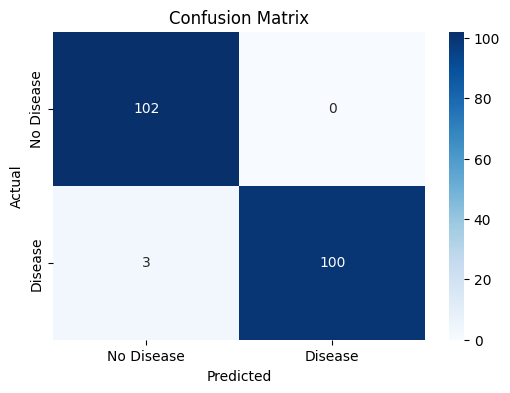

Test ROC-AUC: 0.9846


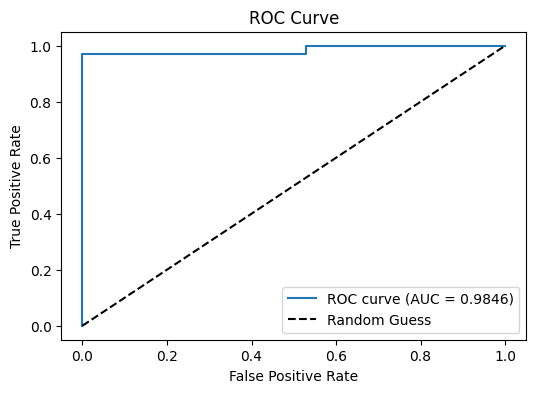

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# -----------------------
# 1. Load and Preprocess Data
# -----------------------
# Load dataset
df = pd.read_csv("heart.csv")

# Apply winsorization to numerical features (excluding target) to reduce the influence of outliers
for col in df.columns:
    if df[col].dtype != 'object' and col != 'target':
        df[col] = winsorize(df[col], limits=[0.05, 0.05])

# Separate features and target
X = df.drop(columns=["target"]).values
y = df["target"].values

# -----------------------
# 2. Split and Scale Data
# -----------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

# Create TensorDatasets and DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset  = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=batch_size)

# -----------------------
# 3. Define the Neural Network Model (PyTorch)
# -----------------------
class HeartNet(nn.Module):
    def __init__(self, input_dim):
        super(HeartNet, self).__init__()
        self.fc1 = nn.Linear(input_dim, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 1)  # Output layer for binary classification
        
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)  # No activation here because we'll use BCEWithLogitsLoss
        return x

input_dim = X_train.shape[1]
model = HeartNet(input_dim)

# -----------------------
# 4. Define Loss Function and Optimizer
# -----------------------
# BCEWithLogitsLoss combines a Sigmoid layer and the BCELoss in one single class.
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# -----------------------
# 5. Train the Model
# -----------------------
num_epochs = 100

model.train()  # Set model to training mode
for epoch in range(num_epochs):
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()           # Zero the gradients
        outputs = model(batch_X)        # Forward pass
        loss = criterion(outputs, batch_y)  # Compute loss
        loss.backward()                 # Backward pass (compute gradients)
        optimizer.step()                # Update parameters
        
        epoch_loss += loss.item() * batch_X.size(0)
        
    epoch_loss /= len(train_loader.dataset)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}")

# -----------------------
# 6. Evaluate the Model
# -----------------------
model.eval()  # Set model to evaluation mode
with torch.no_grad():
    # Get outputs on the test set
    test_outputs = model(X_test_tensor)
    # Apply sigmoid to convert logits to probabilities
    test_probs = torch.sigmoid(test_outputs)
    # Convert probabilities to binary predictions (threshold = 0.5)
    test_preds = (test_probs >= 0.5).float()

    # Convert tensors to numpy arrays for evaluation
    y_test_np = y_test_tensor.numpy()
    test_preds_np = test_preds.numpy()
    test_probs_np = test_probs.numpy()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test_np, test_preds_np, target_names=["No Disease", "Disease"]))

# Confusion Matrix
cm = confusion_matrix(y_test_np, test_preds_np)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve and AUC Score
auc_score = roc_auc_score(y_test_np, test_probs_np)
print("Test ROC-AUC: {:.4f}".format(auc_score))

fpr, tpr, _ = roc_curve(y_test_np, test_probs_np)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label="ROC curve (AUC = {:.4f})".format(auc_score))
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
